In [1]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt

from astropy import units as u
from astropy import constants as const

import matplotlib.pyplot as plt
import numpy as np
from ipywidgets import interact, FloatSlider

from pathlib import Path
import sys

# Use this checkout when running from the repository root or example/.
for root in (Path.cwd(), Path.cwd().parent):
    if (root / "src" / "redwine" / "kernels.py").is_file():
        sys.path.insert(0, str(root / "src"))
        break

from redwine import kernels

In [2]:
E0 = 7. # keV

N0 = 1 # rest frame flux per unit solid angle

# Normalized emission line profile
N0 = 1 / (4*np.pi)

Emin = 5. # keV
Emax = 10. # keV
dE = 0.001 # keV
energies = np.arange(Emin, Emax+dE, dE)

is_photonflux = True

interactive(children=(FloatSlider(value=0.05, description='β', max=0.5, min=0.05, step=0.01), FloatSlider(valu…

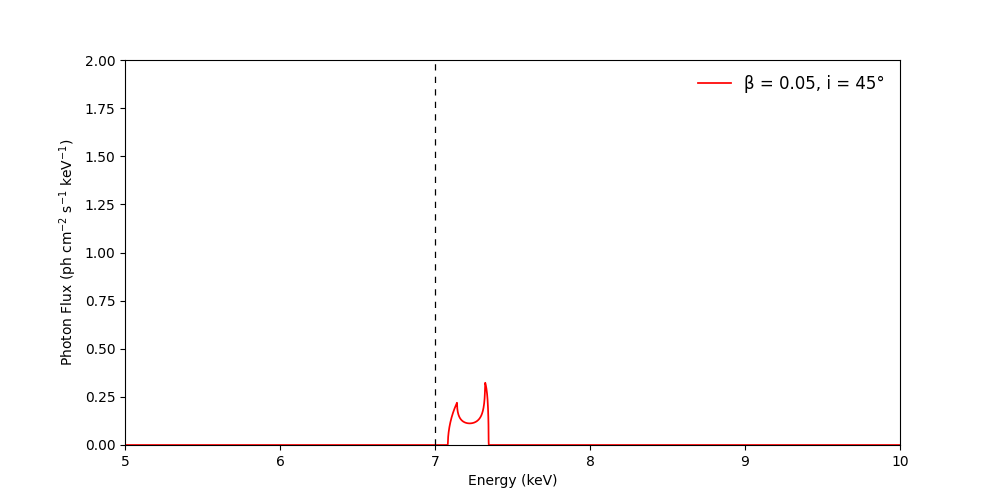

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
line, = ax.plot([], [], color='red', lw=1.25)
ax.set_xlabel('Energy (keV)')
ax.set_ylabel('Photon Flux (ph cm$^{-2}$ s$^{-1}$ keV$^{-1}$)')
ax.axvline(x=E0, color='black', lw=0.9, dashes=(5, 5))
ax.set_xlim(Emin, Emax)
ax.set_ylim(0., 2.)

# Define plot function with parameter values as inputs
def plot_spectrum(beta, incl, thetain, thetaout):
    i_rad = incl * np.pi/180 # convert deg to rad
    thetaout_rad = thetaout * np.pi/180 # convert deg to rad
    thetain_rad = thetain * np.pi/180 # convert deg to rad
    y = kernels.lineshape(energies, E0, norm=4*np.pi*N0, beta=beta, incl=i_rad, theta_in=thetain_rad, theta_out=thetaout_rad,
                              is_photonflux=is_photonflux)

    # Update the line data
    line.set_data(energies, y)
    ax.legend([f'β = {beta:.2f}, i = {incl:.0f}°'], loc='best', framealpha=0, prop={'weight':'normal', 'size':12})
    plt.draw()

# Create sliders using FloatSlider
beta_slider = FloatSlider(value=0.05, min=0.05, max=0.5, step=0.01, description='β')
i_slider = FloatSlider(value=45, min=0, max=90, step=1, description='i (deg)')
thetain_slider = FloatSlider(value=20, min=0, max=45, step=1, description='θin (deg)')
thetaout_slider = FloatSlider(value=30, min=20, max=90, step=1, description='θout (deg)')

# Use interact to update plot based on selected parameter values
interact(plot_spectrum, beta=beta_slider, incl=i_slider, thetain=thetain_slider, thetaout=thetaout_slider)

plt.show()